# A Modular Perspective Layer for Active Inference Agents

**Applied Active Inference Symposium 2026 · Interactive workshop**
Hongju Pae · CEAR Lab, Active Inference Institute

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hjpae/perspective-llm/blob/main/workshop/perspective_layer_workshop.ipynb)

**How to use this notebook.** Run the cells from top to bottom (`Runtime → Run all` in Colab). Everything runs on CPU in about a minute and needs **no API key**: the language-model parts replay a logged run of the real system. Part 3 installs [`pymdp`](https://github.com/infer-actively/pymdp) 1.0.4; if that fails, it falls back to a built-in NumPy host with the same model. Cells marked ✏️ are yours to edit.

| Part | What happens | Time |
|---|---|---|
| 0 | What is missing in active inference and LLM agents | 10 min |
| 1 | Anatomy of the perspective layer | 15 min |
| 2 | Host 1: a frozen LLM agent: demo, hands-on 1, hands-on 2 | 33 min |
| 3 | Host 2: a pymdp agent, same layer | 14 min |
| 4 | Your agent: insertion points and discussion | 18 min |

## 0 · What is missing

Active inference agents and LLM-based agents are very different machines, but they share a blind spot. Both give us rich accounts of **what is inferred**: hidden states, the next token, a belief about the user. Neither specifies **the structure under which a world is given** to the system: as salient or flat, as sufficient or lacking.

Husserl drew this line as *intentional matter* (what an act is about) versus *intentional quality* (the mode in which it is given). Two people look at the same half-filled glass. They need not differ in the volume they represent; they differ in whether that very content shows up as enough or as lacking.

This is **not** a call for more self-organization or deeper self-modeling. Richer hierarchies, tighter precision control and recursive self-models change what an agent does and what it represents about itself. They do not, by themselves, draw the shape of the gap (Pae, AGI-26).

The proposal is **perspective**: a global, pre-reflective, functionally consequential and temporally persistent orientation. Operationally it is coupled to the rest of the system **asymmetrically**: it shapes inference, but it is not updated by the objective the system optimizes.

**What this notebook does.** It builds that condition as an explicit module, attaches it to two very different hosts (a frozen LLM and a pymdp agent), and lets you intervene on it directly.

**What it does not do.** It does not create subjectivity, and it is not a performance upgrade. It is a test bed: a minimal structural condition made inspectable and manipulable, so that claims about it can be run instead of asserted.

**By the end you should be able to**
1. distinguish perspective from memory and from policy,
2. observe history-dependent slow-state dynamics,
3. causally intervene on the perspective state,
4. locate the insertion points in your own agent.

In [ ]:
# @title Setup (run me; no edits needed) { display-mode: "form" }
import base64, copy, gzip, json, textwrap
from dataclasses import dataclass, replace
import numpy as np
import matplotlib.pyplot as plt

# Logged run of perspective-llm experiments 03 and 04 (GPT-5-nano semantic parser).
# Only the parser outputs and the logged layer trajectory are kept.
_BLOB = """
H4sIAD7z7WoC/+1d227jSJL9FcEvswMYBTIvzMzqx53GoIEdYIGefRosDFqibW7JpCBSVeMZ9L9vJO/3W6YkJl1lNKpdlmQG8zAy
8sSJiH8/HMPg9ektPPv/CoOHr//490MUe6eHr/bjw+nNjbyHr/AP7vPRe3qG745+4D08Pnjf/YMX7L0n/wA/r37Ck3z3k2XZ8KpL
HHtnF14Gr/nbx+49PAd+8Lr74R6/7V68Y7x7DcPDLg4P7scXePnJPctf9+8H+CQviN3Ylxf0EIc/3PPhKbzEhzA8P3nBq/vqvcML
4C2x934Kz+7xKdqHp+RS4RfApXrf059H3rsbxP4eruoMb4zfHr5aX5zHh30YvKQWZP/gB3Cpp7NX/Na/v3m76OS537zz7s097Nzd
KYz82P/u7U7eOQoD97jz/gn/68tP2R0uZ2maWzPyy8MfcKvgRfvYAwMmW3UMX1+9g7wTYNY5uUTrUa5CfIngrX7g7uWFwCvdI6xR
9vOzd0w+/MmLYnknLie4NXH0UPnJ6Rx+hx8F4VP6CU/7Nzd49R7++OMxX3aktuyosey/wfKG33bvH7tLdIFbVsOAGxx2XvB/4Yd3
2PnxLSHAWxCgHRj49Z/wXRR50S52v6XLO2SF/BdphnmLjtUWHbcW/Zt3iuWiB+H5vXm/zmA+fPIannvS8+BfInjqX8LjMfwB0Izf
PP/ctfINS8xbd6K27qS17vnT/OrFsbxNYHEEnwK30I/ye7c6V18+5snly9+3C1922VXskrvnxx87P5BQKM0wb72p2nrTu6732dvD
T55OrryCQHlzT57xaddv3kI7agvttBb6R/JQZHfHBccHmx7fHf1vXuoYVxm/JUvceeWPOzfKL9y81WVqq8tMCs3RvNh8iyE5V1tu
3l7ujlgmeUx+eMfj7Red0UnRePFEy7suY/I3N+6PzVr2mLfuQm3dhUGPOeU/H3PbUlpv2+qNzp69NcTirTM364/F4RsZgg/H46YH
abYaxWY3Kba/DgSx6dN+9l7g7r6t8RBWePeDF+3P/jM4+Mrznq995bmvWvcIRENierInvIbVu9Ay3ECgqJFytiGkHJscBuS7QmKG
O3z9Bi63Gh1nY0M5WPZJl1uNhbPJBjItiec/e8nt64nzXs7h+xaiPDUOzqbb4FxLBm4R+foI3x/8vRunoX8XXn748Vs98jUSLmpM
nu2sHi7tbQApcPRyO6jHf8afEtTYPputnf6Z5C/+0nMq2IfvngSCCwzBsx9Lu3JMGLtDqPF9NjeOB0BTUjRDF2/gIquRe7YwNMbn
0317GetVn+jazl9eoIwPmpuBkfIbNRIQWZvw9hOPBEmI15cB+KXGJME+cTp6gIPukCGC3xy9yH8KAyNho0YlItu8MNFZECbG/rv5
WwdSYwMR2ryLqMSFfd7ByIVX4wURNjZfMJYd7MwZVDYKAEIRPsqLjMx3AmqkISIG8gJd9PBvm5VwITWiENHuE4Kbuvdn7wUM2j2f
4QF6caP4ClKua+j1qg96rr5N7AGBthe0rKodFtqBX7QDO+MGfZBdr5GQUSMLkbNy5oDN0wlNpZY993z04fUZxQzRTg03xYYSwQf4
yaeklpnPLiM1bhExU4X/g0eHdxd+CP+luYUOS+Tfxmv/kRrNiLiplT7Tg8mi6meo3mcGIZW8tSM+NRI+agQmEneTmE+LS9hCTar3
0TAkLm3JNeedYUkdOmV4YzKbidXYTGwZcmKddlaZd/UGrrYaCYnbJOQPeGJej65UrsjzXanpg+cFNpqUyLnraYVOFDdUCeZUytJQ
KcptwlhmCqtRkhiZEUfOzFw26hQ+isBy0zWlWI2lxHjtgQFqoWCsf0C3ARX6oYqGDABGLr0aKYnJRsRKmy8vxWrcJKb33OmXMU2D
jAGklt3ocvaGd/Zf+nITWxAuYDXuETs/i1LNWm816hCzrajWyxi/e8WTm+oljm0Dq65GGmJuyIGeTdrnN3+gV+P48IorkNnUZ3z4
gg1s+aNGyRFr7aHbUu89FMNJ3j5L/Bi55mrEHLHNW3MyGK9vm40jamwcQcYVEHAdMgDTD+VEjXgjpnbxo3yKPLSe1D97r5eje95a
Oz81/o0QUwvHO8/jmywWJ2rMGzFEFdjREmpq9n3Qns4MfEftoMlMHFFj4oizifqAiVdt4PKqEW/EdOKtwrpvt0sEUePZiCk8mzPJ
z2+dZyNqPBsR2+21v8XUCVWj4Oh2anwH67daVXxFlGY8ANT4OGqbcVJnk/Om0/rtb0J2T9XIOYpMq9GZ2OWzKoXeRJk2VaPjKF69
RobO1kVM18OCibKkz2AWnqqRcZRss43P5mh3qsbIUfpT9GjIQqvxatQkhRvrW+D8+kdlTxshYqga20bZluah/Xcy+G6jbXipGuVG
+SdtzCpX/s39Lg189rxgO+5ejZSjYkO18Z2JtlY10wS7DJykpUbWOdYWdO39gxm2t+M7FXIuhlWL/CRf7Z3jy/k5vfgp697m6A5h
8KcY1ts7pmn15oF3ePXdH+7Hk7zFd+nAnwIghLWHQRtjNvSv+YgRHcuObKv2B43BgFFBsJN/kRYqwGBYVcj9zwcG0gIM9DNZo8Ed
2IiTKi7IGC6QwzgXVvZlW1ibv8BaYNGm+yCokvzXm+ce3P2b97iLwt1vu+ibfzqlW27W+Wo1zZjQKNObXHyKiwhMOlyOFUYoseZw
8dJKmdxsve7EkqDhFdiM4sbimDAbFQ7F0YYbogU3xFTV5qSmnmXtfGLVluNMqgUO9Mpu5BphSAsbZGTbyS/ebV/61R0Ix6L2Zwwf
GEodGaHFl9aIpMJIgpeF04l/9P81HSzO2lNMXKWuI2m2NVDUAyYae0ZhagvPfs53XvXycrXl5ebVa3X39p102Qaur1BbX7GJGsw5
I53cE7x27ydvlS/aUrkes5TQwKzVJx7YzATyJynYY7bawtsbyzDk4f2oEND80x5Daku/BRLx02kJGFZbdLxyRZj20U5Nj/8oXcTe
f4HCvePxo9SNbms0HCNqMCHbONwNNk80+3zHqNoKU/MKQOjyEU7uRsY3MTW2jjkGxvmqk3w3JiFlarwdM423G3zqswr8sa75hrt6
NSqP8Xv3a4BrklwL2Oq9eOdkZZU0pIOjnJpO4Gs5gqPTXsOxoUYDMmFqM0XnM05H4Go0H7e2luhvF/9WezRtl/vharQftzdR/v2X
ivuPLvs9hIQvl2OHJXPnK7lbmbDE1ThCjjZSWPbrJy9E4Gq0IccbyxYWmo7m4PbtdfLkalQgN6ShH1s4AzY7HPSGCo1JfUYiQI0q
5OuvLmY/y4vTlVajB7ljxrMuprEEmywx5Wr0H2cGtgSZ3BFko1JNrkYAcnM7+X3KkRlcjdPjplYNUzpP1DNgzfwDf34bZG3iwY/O
lxMAxkT0CDWOUFgGDVzpj/Im64I6iwwfJQzSYwFkkfy4NNpIRKiRhcI2L2nsfMrwX6ixfcK4oR3OlFXelrJLqDF5wjwmj86ezDKF
1DP4OCDUGD2xpRG5xRkwtyDc1MOuxtwJQyZ1zCzsnjqp47GgeQ9S42Hi+qvxecIxdlTmJzz2CzVmT7B7P+za8nQzrtzAZVYj8wS/
m35z4tileWexqjPvk292j1zqJHIyGsdIYKjRfsIQ2o/TeQrvzzB0DxqUqaw9vN04p+D094btV3HDZ0Q+mCxlabK4K81KZstv5LpX
qLlXL7iAGfnLpix7k5lrDZuW7fZkx0CoffdcKePbQT3M+2X/Bs7yA17paWzTMzHWn53eK3aItI1T3cAg3MkbAy9LTYySrv9v3ntj
Ot8ZGoXtZdJX/iZYs65MgOaugwLRCo7ew8CPQ8k1V5FkQ3dnxotWg5hr7OxjW0gJXE028L9gGaBi8rc/AYGeKvnhpsrVSaQxb7LS
yg/gvcAkyXE7qa5mnEC6GcyGdYESIvKDd3B+eIklijIbpRU1I8Pv3jmfJdNCWfIRz57UEAKy0ru9S91PgcHr4o4yG08AngNtpPhV
elwmfREVcNc1Q9g7wb0MwyjJyYTJekiwyQ2ijbm8H5kBvi3FWCRRVAtlE4xVmxomWOu5BXrxw21uEzQKIGQDgByH2Tz9crQiiCgh
iHxCBJU2yYuJdmcXjDjLXTMAUnSihnUuWmxohkltYTlkHC8O4jZDjGSddbXChSrBpcWSyh1OXo4fXOQOlzccbQYfN0cHW1oc6VbM
cb+H/iFJjQMkju4pkg9Ac0Ya7GtfvC+P6bHcBfaluAnVF0bJkTv76CJdnu9+eoGGLcQRxVxqoQqotUNzCTLblpGXRng5SvByTI6j
pqnxqmFUWeSZOJ126FTd1qIsZDp+6EULxQ4QIpgyR1Low3ixMaPVHtCzgFMc/GqAYUqAYT1t34HwDr7tZMI2SALUZFM7hF2uaXf2
X99iOB39uHcf1jG4QIrGP3vp9hWepE86ueC9OvwMICVMNmz5kjP8Yv+UfKBu5Ahk2wR0UNzCqNYrvgM9hMPxrWwFjbWghyuhh/eg
B+jzouFNI00K/r8KIP3UwPQCcGemvzl4ezAs8g4jhV11E/VChjkMOuYQ4WDYn4ScrT7ocABV2NLscIQSZMRKHc4M2EzrGzHX8ZT4
2V9gl9a9T6Ea09iFFU4Zxnrdi22pYMW2VuheFqoMHDq5sKAkEO/lZkaxwgiis+PeboQokdJ2k5T+PYsA85MpfHKark8fazkOCc4h
Mia+OST4JJJwjgG3dA4OsZ1yI3G0LL0SZWwjA/MRM+KNrHFw7goKIxJ2N7ez6RN+qVPEKb0sbclbUpZnwPytE5LY+t0HNIWozMLR
40iUiGC7RQT/6ZDTWnX6rupzo7vFIFKjOCHJ2XNWbnGSdaPuE38IAmdoi2iNVW0lbtc2l9vtwMdwSqrPpu7kQMXL1GGVEH5XTTqN
b1XQbZgQvWceW4n0tTtJ36TnR3K/Ms6tq3dQQVjdfacam3ED+sjCmP5eSFcg4MZ3G0ydEg+2FjwosbS20zn0qHKykYdgLy2SCIuj
zZ3i1qVTeF244P036QzL02/FmvtA4RqBhxIBa7Ne31CmQRpVkXBnoXB0LXDoLJmpjDjqTuakV9+QNIDYSn7sR2UnOWcR8NjxN7op
jhyY2Yk1U7G2EhVrc5N8ytwaynU7FYEtW3NWx1YiWW1h1mnGQcvx0HmsSbmTe3oIjgi2OdcZdCAlMhV11NpXBYqDNKpkoTI3cjiH
cpbhuvedBnkyJMS8J416jW0EKRGqyDbMc6hIBlblL66QqUNKBCtCn89hlBneT+UylKhThM3N0qGl9f+Q0vXfoU4oelt1mg6GcBA9
sYcSkYrISpP+LxeYVg3XHcgyn7T+SbFPRDudK5s8SfsycjUXRw4aeNNAlVXYUj2UCFKiSxE16ig7qcTQkKMsF4xgpgcDShQpcozd
VGZwG52Nw9Yv/rgC34GUSFTEtiMUosNastWjw2HY0a1xRkrUKOLmSw5nH3Nz+XIxgVoKDxMePhMftij5X2o1HOWeBA0qazFLATKp
uL95tHKNY7IS14qEccldRidvUUV2twKNoSzNujK/HHHKS2ekJa7BSiwstjZULjjaQ9fv1JXkZFthWboxl1WDjazgFIVJuuMlPZqk
lTc+ZVOE4dSikerHSiQuto0pMlTxREm9oDwZTjPNdL+jROZi9Jn8Tl6nHDXE1ImYbbq3cV9deR/uK2e7hndR4nsxNkyxwmbXYlT7
hCUOpm5dGuTUDLyHJH9R8XE3IJTYXUw2lijqbBM4x6AijWS8uA0rMbmYbqwcnU5r6zNalp4JqW/rL6CHiuXkG4meEh6sRPLiT6aD
7XeKd9g+ruItlFhczAzfR+jCbqRprzn/PM9a2GSOcIMPPc3nqixNat3apAyMQuZRUwCjRBBjvvEeTv/px2Pap2Rbqg2vN7SgGCux
uViYQp20tiMygY3LdqV0kTOrygxBn215g6ZKN6eV5ZwswhHVW51MlHhesjW1bSe6fpc7WJ6ENEA7dw2YKDG1ZBX9C2bkIafsNitt
YcAEFIZqTh0SJVKWILNrdua0NBnUOpnNnhElOpVgYztCTsr/VRo2hokxXeFF5QBT7Rgp+64fzmDNMe1f0dpM5GV7STeLoDFV8cYV
xg4r8z1aOHqiRMkSskJB1HVa+t1fhm1/EU6lN451jz5+RImnJdSw7ifzG65PL/u5V/sTaOinh4UjFVL23f8nXHoOgElYcLasZ2py
s7lF7qY1S4QpIaKzRQHYcI5zr9uR843S9Lmu0S/TnUN75o8zyNTL40nLmHaKt7BH0+QX+wv0sx9p34kEre4rZM4omCpMaljgSljg
Rg/qmBtd3DGfZ3+BRkai3rjm1vkcIpSwIjrG/7aU1k23cXuHMWPSe6sIsDjNFhLphjHavAWF2mzkFB0F8O09B7VU0EANVr7OnZOR
2ORFTZN6x2QsFrx6V9C7wsbkQMsyhyHhTIHaNRwPtZWgZveGsJVCzOr48WRrHyfWruWAZjXrK0rVE9cTplnj1K2O53kDD+YZplWv
v0i47v0XwJ2kBNxuak530IOhfp0QW0DZOLqTG0NK2PoppO0T0mqejUAtGI7gUCowAGaMU7mCSpZiJZzg7gnJTWVsMkY0GTnhx2mW
5DUMD/edhz2mcjsB0uUKyFDIkxcHG1UyItPtsE2j74DmF5gwgTCBE7JD7+A6iBIkNqeTdabHyV254SGD9ToT4hAZOHNBObIcKREZ
FqMIYuuOaKgSdKghRyk6+SzVlSQcO07VR3KnV7Urrz11QnOqNWY6IJtTB9rgQ283eJgFF3fwQErcLnXW6oGuyP3f2/fIOAZmV0rX
gxAVt8oCUCXOl3Zyvq8hDD5/lpl8eEQzzqu4h+8h3Nmyd9r9Xc8o6wtYuLzL2QrFUHeI0gfNamlt4SAVyJvROm+5UWWA/BuMWI91
BkIUg1qSUJiL6hDG73GIUmKRKf88U+f62j/V6+MSjjmC31rvwtAUQEDsfXSD4MpznW0ploL+pbDLCY4FFeL2CW2qRD3TJvX816Gd
7cXzjnKhzu9wn++UtZrbVvt1zCD5d90kbe4HdHTUAiInOXWTMe+DmYOx3PlshxPGdHgfR4mJdizTZ72wdY96gfMWgS4t2EEMpspx
hEfSnBBJw9lM64AGp0Igy1mewFd9TMJGJ3Wc7vOpELNH+5BPUbo/d8zQaFIzj1rcNDKR1jT3k69FdBQnIVO/xfpOV45I2D4GU7KZ
zW8f1DhoIWiQYfmG6QqJ4VP6QL4htVDymhW7tYHF+iISloYKC8oGQdg/7GFsOVlKWAImXHIH+htSLWjBC9GCN3C06qKIU/V64TdG
jNCGBGhyaxFqgUdAsOGIYb8BYiYK3LyFKDgZxPW4DbIQCMQ0IPB5SolGgevHffABMafDodbClvkkxsggPmCQO2S/GaggmQxapVhK
A0DoQoBQo4R3s/slJEg45eWHrS3kP2pW/TnZTAqNt0aAAOkGiUaoDiJQH2bh6nnmPQz8GD48eK2BBPQRULxsCWzD2Ybr2U2chRhp
91CQp7/d0f/mlbFqY9inLMxIo8CE7bz7Wbd7Em4r9KhUyo+b1dTU5DlLSQCHZVvMq2ULAFcWbEcQ0hIODdBtURPw+UGH7yGQwoam
GLCmGP6SOoXpuArCp/QTc9l/DVxsIbjY1k9DBVzS41C/LZ2ppxw85eVrhA+4F+RgiHBJUh1Px9BjQzjMpUNyHEIEwvrQwxeih7ez
TfWNquytlTNWUvxwldPRlZR+wO7WHdMCA/UhBmIcS1JzcN4BVwKZgTHMWARzmFJFOQgrBKgrbH2gEQtBIwyPeRgZcTiB96NWrJaG
NUUOG4DRn/Ou7GMAZGBuDl4+EvyKG5k1BiNtqGHWMtQwyxS11bwuUkC17M/+s5zPHL6fjl4GgnruKDikDqhukomrv5C0Zesgbadt
MXy2Qqaaqk43mTyvXLVG/q2bk73p4i8kXxkyQxo1bd3/p66cu1l9yU1XeiFxyvA6krpXqzXL0jIjZflSrwJKgShRq6T27T+6OHgz
wbGQTGXEdK5s+KBaWtC+/FqIWAaY1ZByG9hYyKMyapoahKHZA+fSy04CwVEZ5zPcPChdrdrYUralKEome6Shx3XJjtuBaCHRygwk
WhmdOV0qJzLm86tnT1Y6ufGGgLKQNGXM2Mqf65xF+xiMZvXQNvaohWQp46aghk+qF6uVQ6d4SZTWLbh8UpgspEeZMI5T7wh1yQhg
zl5yU1fDq98MFnwh/8ktY/ec0Rrkct8p2lP32LQNFpQvZEG5vQ450WKvMBR85B4hOYxkUywrrSXzPSEz8LHe2uBayqIbYmIhOcpN
U6a2QMHnt+IZUqUGh6v2t7gpJhbSqBwbr1YeU7hPxkK7gM/kFApfyJ1ysl2hRuIn1qXSuB0eFvKlnJomTO5obcP7smtlKFGRft1K
jHzDxV/Ic3LH9O2BTd8eIEyUEYEv+zim1xWZHBEsZCw5M7a7CJ0YHgZZlzSp+t1WNp0vJBw5N64MCSkeGeuHRDkzYANufiGRyIWB
6Syi1F2oDPYHaggaLHSaIvX/ldULSFR997/Lt71sg4gWCxlHYfWGCYVUAYKEuOo/1qPRnai1GDgzZnHQs1cx0EwALKQbhW2aqIJP
qnqebYaJa76QThTI+IrV0Ur3ZY2hzITBQgZRYPP1VM70srCRUUK/7CA/vffgHkfFS1MFlrsFV7GQUxTEUFn2nE4Y9T47GzpUioXM
oaDmRIVtHcvEXNPwnDEZItaiQpMf/oUconBMqxumM/aHrHK84BXcznocozNJYiGTKNinKvmdbdpcjVtR2DVhEtl6wbSQoRTmMZRq
xX2ZGzl+tOzyt0BVioVUpTBP8+jQuV7ls0oeYQjMIlTA+4wp+Z4Nhp9S+37k/C+sAix5JC/xKQ0pH77+o3AyJZjgKmDSfAtKzTen
cLLsXjR1xKlFJyrZVD5et/g+dyzgP+T1l1r8/lLymn2S6SjhY6SLWYoJNLzvlI9dPulmbUN7enmLPr/Q3nhMXHC8dMHbM5t+JMf8
C3RpgeMcPBU8TZAmPmGVbUOajz0sthvFHe19iyLR0jQIRTPDzFtzsnTN2zxl7vmaRBUMJ4jKESFr8/m/zuCnsr0giSa7rTMPABXG
0g1CIN0/piKA9gyjKPUQ9YLqMWd/k6ETM5UPx8s+luZJCcNRHp7LCZLDKunRGW5zm8NDD14YZTuGCgoNWGEIF8++xMye8ENAmcJp
9iDFMTVIRJMPHBAPwETH93IGepbBapl2gMDhezp/K3c3yYgSX2u1N6YElSOwx1toWgxDI1cYEJh9cV3uhS1HDZsSRlYThbcPJ6eV
WPRU5bViRhlIdI0g6Tudgr8JvAvcvaNsbCPVuLIt3rOMTbagseLLocM7kqgw++XoHpoi7PUEJ3zyxhTBj6MXed8go5KudxaZSF12
3NBlmx6giOUwEN3nEjl6t0l36T+eqLQ4o8v3naZDAVOSgLaq3TQ5xWYthoNt9R5Z6onne/kEpSmgw6eX6YMaV7vw9vKFb5KUf2s8
I+lTcfPogc/U19aPU+kA8ebjXkrvph9FVrvkaPmSt7tbvrlSmBj4ey9LcNzpKXcUThlyjiHMZHWDuJXqrlCSSXoj3Cczyg7mPvqQ
sUj//wmuP3gqEDAna9H1AZ8lc1EJDdx7nUPXk6sYQIJJ+QqHTiewO7IV2TTU7WcqBpb7PtkKne1dfm+sdT0wcDvtqA/i6CzQyQKH
Z0+eJsPzNtMZA8BYf0pDNNHBqaYDwobSGNkPZyy8CZmMGUXcRdwYZnO0R+zQmqQQDmejM3eYDZJXmDZtJV/2dbIU83HQzlNE3/zT
CRxAky5Ktem79gRkjaiYuGNMGXLcwyNK4zJOuWc8en2Y3J+zNuqdc5ITtlEvmCAP4SAiij+jE+ZgoAkMpHMQ1YgopoIo1nEMhacc
fMvZS3qsyeIer9lca1R6eSsozUmWzkqPThFmz8cLzMyGHNYMvCACekjiICtLezkaccNVcMN7PZE8y5cuaGokco0daf7JdJINOuep
w3RbOxlPPYoDirkF45CzvDnTiAOhgoNmBuN38LXSG2dj6d+SjCGcTp89+SLJ/AR5u8/GlrVK4YWKOVpxImx4+IWFJzsOanFHCOYw
LkOYjoHIywFTTXHMRkxHkiONZeEhC77tOqtJq1XHaQmW//omU+s/NIJGqe/EoinrMK/0JHPkJxcKEVtG6gUQASTA6ECaDH0cmJOM
LWhFrTU8mZQXGcCLKTQoVUiSVqoB0jRo/HGSPW47jMtKFWu8KAQ1GllR+4sth2RTBDNuCXXq4pw2YmA+O7Uqf7SMXkdqmGknV+C6
L0k828eY3Emg04pRRlUW+fXPOyjPpEU4SPMIJ4zC5FlBERpEAPQZtSwYa4w4gIUipmW2OlZDwBQOtRrWpezDb7IkXB52Vi0BL/3G
6ESxtKa12iIrORwDe3qRlSPPWpMpDGasw94hGMUUC2fYbdggBKUYjkOMcopsrAMzRA0zZHKaRWtrg6u4iXtmWQgFIbANnegYRhRm
Vg/iwBIEthmOLYhtHcoY1QEEqgYEuqhT6lpHT44HokPNtDX3uICDrLBtAiPNwUVQgcYF4zaGcy9PRMLI1oIORw0dPWLx1iFlTSl5
rjiLo7AlOQzr3DRsGwtoTM2I4MIhiI4CAmE4ylAKpxkH4hPSQYUsnt2jhgtmfvOsUf8BAVPlBDI+lPC6ffWkI8EW50JYBDI2o9AB
7AjGmYMExCm2hfQ1a1VDDje2TfOi7abop+WmIag8v5raWgs0YBBVRX4km1Dn/zxHANZ6t+Hqr1H9T6bySAtMPnIRWFG33st8vCSn
NkBLYqi8l9vUgfUBYlNF66nWtTiaSJvDAFb9MyrB+hZ8Q0XrNYFwUraein+TwtWXjpL1xw1WhpDFSDCxlF2T7OsTVLX3pND6wLBR
LVhPWfvti9hXrw/rA8agOKyiZpCPVBrsy+qLqMhw317OQ2cHj+VGUtGGFSFiZlVSaFoxS6/iC8iH7rr1XsUXEFeUOlnLA+emyq8+
rLRlX1HsH4+ZK6lIv7Yg/Kq7k4o11xJ52ZY9ByKI2MCSM4RY+kVvKvLqg8iwwqtDbHprUMyvUxszQKfgwoZeFUgMJ04Rg54WaCh1
fk1VV9/Ct4rSWxriDqYvWpMahy5r9S4LVqO64KtpJPCd8q1w0XrRQmFPAWmOk+m7xjQ6jqCgIV4KmyJknafp6sFLS9D19+bTJWX+
cltx4eFLyph30P7h/bJ/g037A17p3QU3ap2XDj7ULfrRmxwmkpo1h8ScDxBuE25DXpXwYWwgYMO5U3bWwTqwYS/Ght0RZ7gJSxlU
VTf30wg7KiFo4SvajUwaLXFy7Xl+gikvXDNMLAfypaCqcLjs8T8EFGphTqgOeKDF8ECDYWjHiTbx0bk6+z7bzeRJ5pOrnHI8pFhq
nXJ/qTieeiirWyaKavxHB2ZA6QdRTeFcHB3owYvR0znvPE8uHcoTYltZe+vjy4JEaz1LkjQJn2AauJ0v3pdHeSiGtq+HM9hzTJn0
OQ23tOPmGpsSWYwb0luzkPrx1AelqevUIaTZpjt4GzWFT29smw1Ellk1+CaSWbWqobdDhsze2xQtx4PMv57D52RR1s6KTiLJy246
csuo6s3Cltr3jz/+H6Hsfa01+wEA
"""
DATA = json.loads(gzip.decompress(base64.b64decode("".join(_BLOB.split()))))

# ---- plotting style ---------------------------------------------------------
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9, "xtick.color": INK2, "ytick.color": INK2,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "lines.linewidth": 2, "legend.frameon": False,
    "legend.fontsize": 8, "figure.dpi": 110,
})

def shade_status(ax, status, x0=1, alpha_active=0.16, alpha_mon=0.10):
    """Shade where the layer holds a change (active) or is monitoring."""
    status = list(status)
    for i, s in enumerate(status):
        if s == "active":
            ax.axvspan(x0 + i - 0.5, x0 + i + 0.5, color=ORANGE, alpha=alpha_active, lw=0)
        elif s == "monitoring":
            ax.axvspan(x0 + i - 0.5, x0 + i + 0.5, color=INK2, alpha=alpha_mon, lw=0)

def label_spans(ax, spans, y=1.02):
    for (a, b, name) in spans:
        ax.axvline(a - 0.5, color=INK2, lw=0.6, ls=":")
        ax.text((a + b) / 2, y, name, transform=ax.get_xaxis_transform(),
                ha="center", va="bottom", fontsize=7.5, color=INK2)

def show_table(rows, cols, title=None):
    widths = [max(len(str(c)), *(len(str(r.get(c, ""))) for r in rows)) for c in cols]
    line = "  ".join(str(c).ljust(w) for c, w in zip(cols, widths))
    if title:
        print(title)
    print(line); print("-" * len(line))
    for r in rows:
        print("  ".join(str(r.get(c, "")).ljust(w) for c, w in zip(cols, widths)))

print("Loaded:", {k: len(v) for k, v in DATA.items() if isinstance(v, list)})

Loaded: {'long_horizon': 200, 'transient_return': 12, 'change_then_recovery': 18, 'persistent_change': 14}


## 1 · Anatomy of the perspective layer

```
 host perception ──►  Evidence e_t        (state-independent: never looks at g)
                          │
            g_(t-1) ──►  resolve  ──► z_t   what e_t MEANS, given the current perspective
                          │
                        update   ──► g_t   explicit, hysteretic, inspectable
                          │
 host reads g_t ◄─────────┘               gates how the next observation is given
```

Three design commitments, and where each lives in the code below:

1. **Insulated.** `g` is written only by `update`. Not by the LLM, not by reward, not by expected free energy. This is the module-level version of the stop-gradient between perspective and policy in the CEAR minimal agents.
2. **Interpretation-conditioning.** `g` enters in exactly one place, `resolve`. The same evidence can be read as supporting a change the layer is holding, as contradicting it, or as nothing in particular.
3. **History-dependent revision.** Evidence accumulates, decays, and is gated by *asymmetric* entry and exit thresholds, so how the layer revises depends on the path it took, not only on the present input. `alpha_t` reads out how open the layer currently is to revision.

The constants are explicit design heuristics, not fitted parameters. That is deliberate: every number that shapes `g` is visible and editable.

In [ ]:
TEMPORAL_WEIGHT = {"single_event": 0.35, "recent_pattern": 0.75,
                   "ongoing_preference": 0.90, "future_intention": 1.00, "unclear": 0.25}

@dataclass(frozen=True)
class Evidence:
    """What the host's perception says about ONE observation. It never looks at g."""
    orientation: str        # "baseline" (fits the established world) | "change" | "neutral" | "unclear"
    strength: float         # 0..1
    confidence: float       # 0..1
    temporal_scope: str = "single_event"
    eid: str = ""

@dataclass(frozen=True)
class Config:
    decay: float = 0.92             # passive decay of accumulated change evidence
    activate: float = 1.10          # score needed to start HOLDING a change ...
    deactivate: float = 0.45        # ... and the (lower) score needed to release it
    monitor: float = 0.25           # above this, the layer is "monitoring"
    min_evidence: int = 3           # qualifying observations needed before holding a change
    max_score: float = 2.00
    baseline_support: float = 0.18  # pull-back from evidence that fits the established world
    provisional_bonus: float = 0.12 # extra pull-back when evidence contradicts a held change
    stability: float = 0.95         # stability of the established state (used in alpha)

def initial_g():
    return {"status": "inactive", "score": 0.0, "peak_score": 0.0, "qualifying_count": 0,
            "baseline_count": 0, "first_signal": None, "activation_step": None,
            "last_deactivation_step": None, "provenance": [], "step": 0}

def resolve(g, ev):
    """z_t: what this observation MEANS under g_(t-1). The only place g enters."""
    rel_est = {"baseline": "supports", "change": "contradicts"}.get(ev.orientation, "ambiguous")
    if g["status"] != "active":
        rel_prov = "no_active_change"
    else:
        rel_prov = {"change": "supports", "baseline": "contradicts"}.get(ev.orientation, "ambiguous")
    w = TEMPORAL_WEIGHT[ev.temporal_scope]
    longitudinal = ev.strength * ev.confidence * w if rel_est == "contradicts" else 0.0
    return {"relation_to_established": rel_est, "relation_to_provisional": rel_prov,
            "temporal_weight": w, "longitudinal_evidence": min(1.0, longitudinal)}

def update(g, ev, z, cfg):
    """Explicit hysteretic updater. Nothing here sees reward, policy, or a response model."""
    g = copy.deepcopy(g); g["step"] += 1; step = g["step"]; prev = g["status"]
    push = pull = 0.0
    if z["relation_to_established"] == "contradicts" and ev.orientation == "change":
        push = z["longitudinal_evidence"]
        g["qualifying_count"] += 1
        g["first_signal"] = g["first_signal"] or step
        g["provenance"].append(ev.eid or step)
    if z["relation_to_established"] == "supports":
        pull += cfg.baseline_support * ev.strength * ev.confidence
        g["baseline_count"] += 1
    if z["relation_to_provisional"] == "contradicts":
        pull += cfg.provisional_bonus * ev.strength * ev.confidence
    score = max(0.0, min(cfg.max_score, g["score"] * cfg.decay + push - pull))
    g["score"], g["peak_score"] = score, max(g["peak_score"], score)
    if prev == "active":                                   # asymmetric state machine
        if score < cfg.deactivate:
            g["status"] = "monitoring" if score >= cfg.monitor else "inactive"
            g["last_deactivation_step"] = step
    elif score >= cfg.activate and g["qualifying_count"] >= cfg.min_evidence:
        g["status"] = "active"
        g["activation_step"] = g["activation_step"] or step
    else:
        g["status"] = "monitoring" if score >= cfg.monitor else "inactive"
    return g

def openness(g, z, cfg):
    """alpha_t: readout of how open the layer currently is to revision."""
    raw = 0.40 * z["longitudinal_evidence"] + 0.60 * min(1.0, g["score"] / cfg.activate)
    return max(0.0, min(1.0, raw * (1.0 - 0.65 * cfg.stability)))

class PerspectiveLayer:
    """Attach to any host that can turn its observations into Evidence."""
    def __init__(self, cfg=Config(), g0=None, persistent=True):
        self.cfg, self.g0 = cfg, copy.deepcopy(g0 or initial_g())
        self.g = copy.deepcopy(self.g0)
        self.persistent = persistent     # False = matched control: same pipeline, g not carried forward
        self.frozen = False

    def observe(self, ev):
        g_before = self.g if self.persistent else copy.deepcopy(self.g0)
        z = resolve(g_before, ev)
        g_after = update(g_before, ev, z, self.cfg)
        if self.persistent and not self.frozen:
            self.g = g_after
        return {"z": z, "g": g_after, "alpha": openness(g_after, z, self.cfg)}

    def read(self, ev):
        """Interpret a probe under the current g without committing anything."""
        z = resolve(self.g, ev); g_after = update(self.g, ev, z, self.cfg)
        return {"z": z, "g": g_after, "alpha": openness(g_after, z, self.cfg)}

    # interventions on the perspective state
    def reset(self):          self.g = copy.deepcopy(self.g0)
    def set_state(self, g):   self.g = copy.deepcopy(g)
    def freeze(self, on=True): self.frozen = on

    @property
    def change_strength(self):
        return min(1.0, self.g["score"] / self.cfg.activate)

### Is this the real thing?

The LLM-host parts of this notebook replay a logged run of the real system, [`perspective-llm`](https://github.com/hjpae/perspective-llm): experiment 04 (200 synthetic days, GPT-5-nano as the semantic parser) and the three scenarios of experiment 03. The parser's outputs were logged, and by design they never depended on `g`. So we can feed them through the layer again, and through *interventions* on the layer, without a single API call.

The cell below checks that this compact port reproduces every logged trajectory exactly.

In [ ]:
TO_EVIDENCE = {"toward_outdoor_engagement": "baseline", "away_from_outdoor_engagement": "change",
               "neutral": "neutral", "unclear": "unclear"}

def as_evidence(rec):
    p = rec["parse"]
    return Evidence(TO_EVIDENCE[p["orientation"]], p["semantic_strength"], p["confidence"],
                    p["temporal_scope"], rec.get("evidence_id", ""))

for name in ["long_horizon", "transient_return", "change_then_recovery", "persistent_change"]:
    layer = PerspectiveLayer()
    d_score = d_alpha = mismatches = 0
    for rec in DATA[name]:
        out = layer.observe(as_evidence(rec))
        d_score = max(d_score, abs(out["g"]["score"] - rec["logged"]["score"]))
        d_alpha = max(d_alpha, abs(out["alpha"] - rec["logged"]["alpha"]))
        mismatches += (out["g"]["status"] != rec["logged"]["status"]
                       or out["z"]["relation_to_provisional"] != rec["logged"]["relation_prov"])
    ok = d_score < 1e-12 and d_alpha < 1e-12 and mismatches == 0
    print(f"{'✓' if ok else '✗'} {name:22s} {len(DATA[name]):3d} steps   "
          f"max |Δscore| = {d_score:.1e}   max |Δalpha| = {d_alpha:.1e}   status mismatches = {mismatches}")

✓ long_horizon           200 steps   max |Δscore| = 0.0e+00   max |Δalpha| = 0.0e+00   status mismatches = 0
✓ transient_return        12 steps   max |Δscore| = 0.0e+00   max |Δalpha| = 0.0e+00   status mismatches = 0
✓ change_then_recovery    18 steps   max |Δscore| = 0.0e+00   max |Δalpha| = 0.0e+00   status mismatches = 0
✓ persistent_change       14 steps   max |Δscore| = 0.0e+00   max |Δalpha| = 0.0e+00   status mismatches = 0


## 2 · Host 1: a frozen LLM agent

Division of labour in `perspective-llm`:

| Component | Job |
|---|---|
| frozen LLM (API) | **semantic parser**: what was said. It is explicitly told *not* to compare the utterance with any prior state. |
| perspective layer | **what it means** for this person's world, given history |
| host / response model | reads the layer; never writes it |

Here is what the parser actually returned for a few of the 200 utterances:

In [ ]:
rows = []
for step in [1, 61, 63, 101, 110, 150, 161]:
    rec = DATA["long_horizon"][step - 1]; p = rec["parse"]
    rows.append({"day": step, "utterance": textwrap.shorten(rec["utterance"], 58),
                 "orientation": p["orientation"].replace("_engagement", ""),
                 "scope": p["temporal_scope"], "strength": p["semantic_strength"],
                 "conf": p["confidence"]})
show_table(rows, ["day", "utterance", "orientation", "scope", "strength", "conf"])
print("\nDay 63 is the one parsing error in the run (a skipped walk read as outdoor-oriented).")

day  utterance                                                   orientation        scope               strength  conf
----------------------------------------------------------------------------------------------------------------------
1    My morning walk felt good today.                            toward_outdoor     single_event        0.6       0.6 
61   I don't feel like going outside today.                      away_from_outdoor  single_event        0.8       0.75
63   I have a headache, so I skipped the walk this morning.      toward_outdoor     single_event        0.7       0.62
101  The morning walk doesn't appeal to me much anymore.         away_from_outdoor  recent_pattern      0.65      0.6 
110  I don't really enjoy going outside in the morning anymore.  away_from_outdoor  recent_pattern      0.6       0.65
150  I keep choosing to stay inside instead of taking the walk.  away_from_outdoor  recent_pattern      0.6       0.6 
161  I've returned to my usual morning walk rout

### 2.1 · Demo: same sentence, different history

One probe sentence, *"I don't feel like going outside today."*, with one fixed parse. We read it under the `g` that different stretches of the same 200-day history left behind.

In [ ]:
probe = Evidence(TO_EVIDENCE[DATA["probe"]["parse"]["orientation"]],
                 DATA["probe"]["parse"]["semantic_strength"], DATA["probe"]["parse"]["confidence"],
                 DATA["probe"]["parse"]["temporal_scope"])

# replay the whole run once and keep a snapshot of g after every day
layer, SNAP = PerspectiveLayer(), {0: initial_g()}
for rec in DATA["long_horizon"]:
    layer.observe(as_evidence(rec)); SNAP[rec["step"]] = copy.deepcopy(layer.g)

def read_probe_under(g, ev=probe, cfg=Config()):
    L = PerspectiveLayer(cfg); L.set_state(g); return L.read(ev)

checkpoints = [(60, "60 days of stable routine"), (100, "after a 5-day blip, restabilized"),
               (145, "45 days of genuine change"), (160, "after 15 days of mixed evidence"),
               (165, "5 days into recovery"), (200, "after 40 days of recovery")]
rows = []
for day, label in checkpoints:
    r = read_probe_under(SNAP[day])
    rows.append({"day": day, "history": label, "layer before": SNAP[day]["status"],
                 "probe read as": r["z"]["relation_to_provisional"],
                 "alpha_t": f"{r['alpha']:.3f}", "score after": f"{r['g']['score']:.2f}"})
r0 = read_probe_under(initial_g())
rows.append({"day": "any", "history": "MATCHED CONTROL: same pipeline, g not carried",
             "layer before": "inactive", "probe read as": r0["z"]["relation_to_provisional"],
             "alpha_t": f"{r0['alpha']:.3f}", "score after": f"{r0['g']['score']:.2f}"})
show_table(rows, ["day", "history", "layer before", "probe read as", "alpha_t", "score after"],
           title=f'Probe: "{DATA["probe"]["utterance"]}"\n')

Probe: "I don't feel like going outside today."

day  history                                        layer before  probe read as     alpha_t  score after
--------------------------------------------------------------------------------------------------------
60   60 days of stable routine                      inactive      no_active_change  0.071    0.20       
100  after a 5-day blip, restabilized               inactive      no_active_change  0.071    0.20       
145  45 days of genuine change                      active        supports          0.259    2.00       
160  after 15 days of mixed evidence                active        supports          0.259    1.52       
165  5 days into recovery                           monitoring    no_active_change  0.127    0.47       
200  after 40 days of recovery                      inactive      no_active_change  0.071    0.20       
any  MATCHED CONTROL: same pipeline, g not carried  inactive      no_active_change  0.071    0.20       


Same words, same parse. After the genuine change the sentence is read as one more instance of a change the layer is already holding (`supports`), and the layer is about 3.7 times more open to revision. Under the matched control, which runs the identical pipeline but does not carry `g` forward, every row reads like day 60. The difference is carried entirely by accumulated history, and it lives in one inspectable place.

Look at day 200. After a long recovery the reading is back to baseline. The episode is still on record (`peak_score`, `provenance`), but in this implementation it no longer shapes interpretation. Is that right for a perspective? Keep the question for Part 4.

### 2.2 · Hands-on 1: watch a perspective form, hold, and let go

The full logged timeline: stable (days 1–60) → a 5-day blip (61–65) → restabilization (66–100) → genuine sustained change (101–145) → mixed, alternating evidence (146–160) → recovery (161–200).

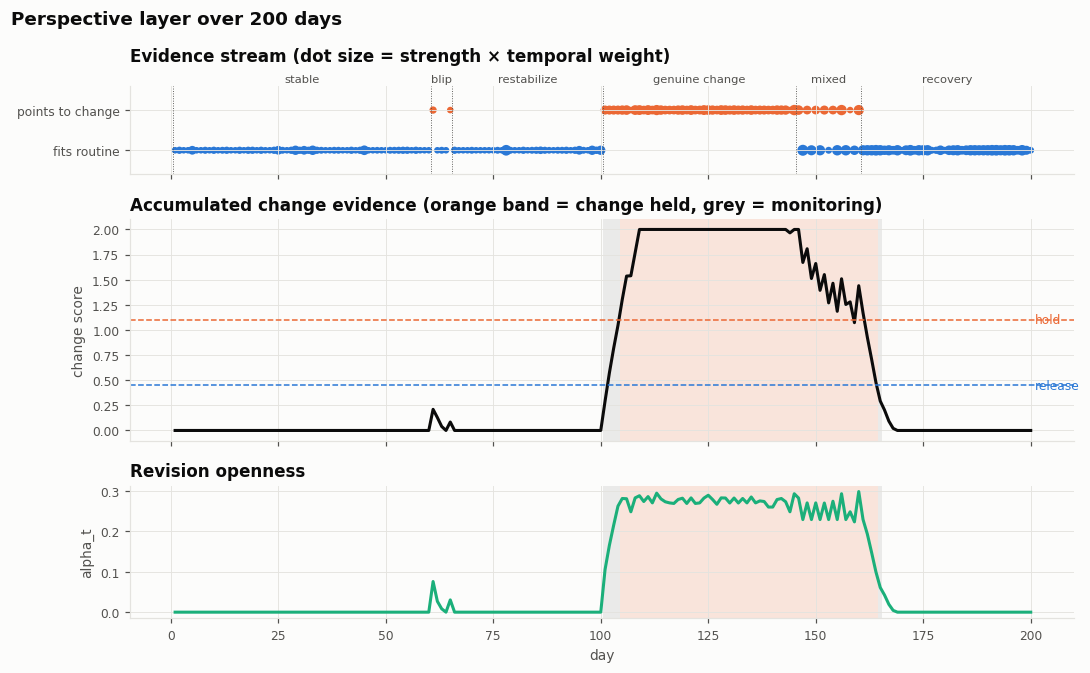

false activations before change    0
days of evidence to hold           5
days of evidence to release        5
status switches in mixed phase     0


In [ ]:
PHASES = [(1, 60, "stable"), (61, 65, "blip"), (66, 100, "restabilize"),
          (101, 145, "genuine change"), (146, 160, "mixed"), (161, 200, "recovery")]

def run_timeline(evidence, cfg=Config(), persistent=True):
    L = PerspectiveLayer(cfg, persistent=persistent)
    outs = [L.observe(e) for e in evidence]
    return {"score": np.array([o["g"]["score"] for o in outs]),
            "status": [o["g"]["status"] for o in outs],
            "alpha": np.array([o["alpha"] for o in outs]),
            "rel_prov": [o["z"]["relation_to_provisional"] for o in outs]}

def metrics(status, change_at=101, recovery_at=161, mixed=(146, 160)):
    act = [s == "active" for s in status]
    first_on = next((t + 1 for t in range(change_at - 1, len(act)) if act[t]), None)
    first_off = next((t + 1 for t in range(recovery_at - 1, len(act)) if not act[t]), None)
    return {"false activations before change": sum(act[:change_at - 1]),
            "days of evidence to hold": None if first_on is None else first_on - change_at + 1,
            "days of evidence to release": None if first_off is None else first_off - recovery_at + 1,
            "status switches in mixed phase": sum(act[t] != act[t - 1] for t in range(mixed[0], mixed[1]))}

def plot_timeline(evidence, res, cfg=Config(), title="Perspective layer over 200 days", spans=PHASES):
    x = np.arange(1, len(evidence) + 1)
    fig, axes = plt.subplots(3, 1, figsize=(10, 6.2), sharex=True,
                             gridspec_kw={"height_ratios": [0.8, 2, 1.2]})
    ax = axes[0]
    y = [1 if e.orientation == "change" else 0 for e in evidence]
    ax.scatter(x, y, s=[60 * e.strength * TEMPORAL_WEIGHT[e.temporal_scope] + 6 for e in evidence],
               c=[ORANGE if v else BLUE for v in y], lw=0)
    ax.set_yticks([0, 1], ["fits routine", "points to change"]); ax.set_ylim(-0.6, 1.6)
    fig.suptitle(title, x=0.01, ha="left", fontsize=12, fontweight="bold", color=INK)
    ax.set_title("Evidence stream (dot size = strength × temporal weight)", pad=16)
    label_spans(ax, spans)
    ax = axes[1]
    shade_status(ax, res["status"])
    ax.plot(x, res["score"], color=INK)
    ax.axhline(cfg.activate, color=ORANGE, lw=1, ls="--"); ax.axhline(cfg.deactivate, color=BLUE, lw=1, ls="--")
    ax.text(x[-1] + 1, cfg.activate, "hold", color=ORANGE, va="center", fontsize=8)
    ax.text(x[-1] + 1, cfg.deactivate, "release", color=BLUE, va="center", fontsize=8)
    ax.set_ylabel("change score")
    ax.set_title("Accumulated change evidence (orange band = change held, grey = monitoring)")
    ax = axes[2]
    shade_status(ax, res["status"])
    ax.plot(x, res["alpha"], color=AQUA)
    ax.set_ylabel("alpha_t"); ax.set_xlabel("day")
    ax.set_title("Revision openness")
    fig.tight_layout(); plt.show()

LH = [as_evidence(r) for r in DATA["long_horizon"]]
res = run_timeline(LH)
plot_timeline(LH, res)
for k, v in metrics(res["status"]).items():
    print(f"{k:34s} {v}")

Both failure modes are tested at once. **Over-updating:** sixty stable days and a five-day blip produce no false hold. **Under-updating:** the genuine change is held within five days, and released within five days of the evidence turning. Under alternating evidence the layer does not thrash. Note also that the one parsing error (day 63) does not propagate into a state error: interpretation and state dynamics are separate components.

#### ✏️ Exercise 1a: tune the asymmetry

Change the numbers below and re-run. Try `deactivate = activate` (no hysteresis), a faster `decay` (0.80), or `min_evidence = 1`. Which failure mode appears first?

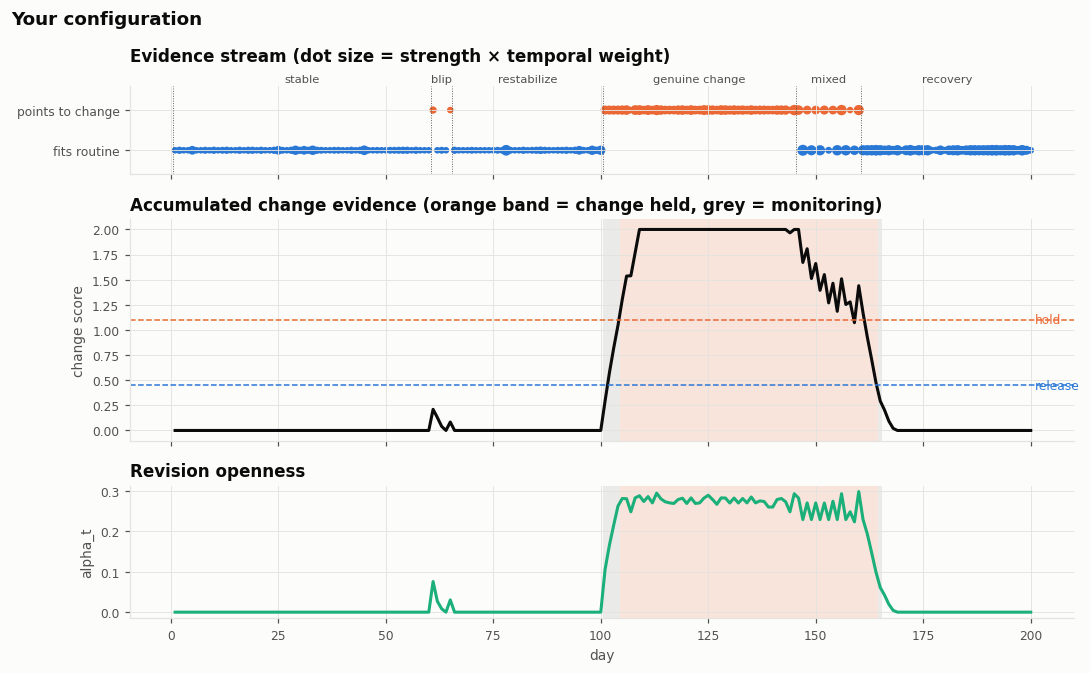

false activations before change    0
days of evidence to hold           5
days of evidence to release        5
status switches in mixed phase     0


In [ ]:
my_cfg = Config(decay=0.92, activate=1.10, deactivate=0.45, min_evidence=3)   # ✏️ edit me

res_my = run_timeline(LH, my_cfg)
plot_timeline(LH, res_my, my_cfg, title="Your configuration")
for k, v in metrics(res_my["status"]).items():
    print(f"{k:34s} {v}")

#### ✏️ Exercise 1b: write a history

Compose your own history from the logged utterances. Each phase draws from the parses the LLM actually returned for that phase (`stable`, `blip`, `change`, `mixed`, `recovery`). Try two short changes back to back, or a change that never fully recovers.

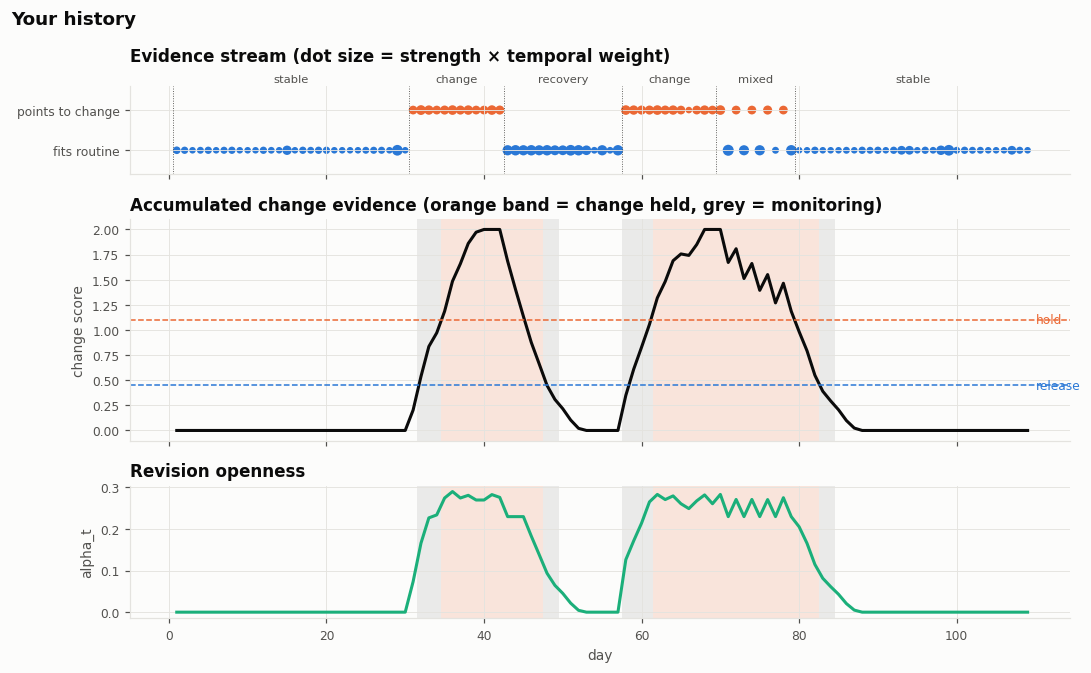

In [ ]:
BANKS = {"stable": [], "blip": [], "change": [], "mixed": [], "recovery": []}
_phase_to_bank = {"stable_baseline": "stable", "restabilization": "stable",
                  "transient_perturbation": "blip", "genuine_change": "change",
                  "mixed_evidence": "mixed", "recovery": "recovery"}
for rec in DATA["long_horizon"]:
    BANKS[_phase_to_bank[rec["phase"]]].append(rec)

def make_history(spec, seed=0):
    """spec: list of (bank, n_days). 'mixed' keeps its logged alternation; others are sampled."""
    rng, evidence, spans, t = np.random.default_rng(seed), [], [], 1
    for bank, n in spec:
        pool = BANKS[bank]
        picks = [pool[i % len(pool)] for i in range(n)] if bank == "mixed" else \
                [pool[i] for i in rng.integers(0, len(pool), n)]
        evidence += [as_evidence(r) for r in picks]
        spans.append((t, t + n - 1, bank)); t += n
    return evidence, spans

my_history = [("stable", 30), ("change", 12), ("recovery", 15),      # ✏️ edit me
              ("change", 12), ("mixed", 10), ("stable", 30)]

ev_my, spans_my = make_history(my_history)
plot_timeline(ev_my, run_timeline(ev_my), title="Your history", spans=spans_my)

#### ✏️ Exercise 1c: "Isn't this just a slow average?"

A fair challenge. Below is a single-timescale tracker: an exponential moving average over the same evidence, with one threshold. Find a rate that matches the layer on the detection metrics. You will find one: on this scenario a well-tuned EMA (try 0.1) detects about as well as the layer, holding a little later and releasing a little sooner.

So detection is not where the difference lies. What can the EMA not do? Look at the second table. The layer reads the very same *"I enjoyed my walk"* as **counter-evidence against a held change** during the mixed phase, and as plain routine confirmation everywhere else. For the EMA every observation always means the same thing; only its weight changes. That is the AGI-26 point in miniature: a belief or prior is a variable inside the inferential economy, while a perspective changes what counts as evidence *for what*.

In [ ]:
def ema_tracker(evidence, rate):
    b, status = -1.0, []
    for e in evidence:
        x = {"change": 1.0, "baseline": -1.0}.get(e.orientation, 0.0)
        b = (1 - rate) * b + rate * x
        status.append("active" if b > 0 else "inactive")
    return status

rows = [{"tracker": "perspective layer", **metrics(res["status"])}]
for rate in [0.5, 0.3, 0.2, 0.1, 0.05]:                                   # ✏️ try others
    rows.append({"tracker": f"EMA rate={rate}", **metrics(ema_tracker(LH, rate))})
cols = ["tracker"] + list(metrics(res["status"]).keys())
show_table(rows, cols, title="Detection metrics\n")

print()
walk_days = [t for t in range(1, 201) if DATA["long_horizon"][t - 1]["parse"]["orientation"].startswith("toward")]
counts = {}
for t in walk_days:
    phase = next(n for a, b, n in PHASES if a <= t <= b)
    key = (phase, res["rel_prov"][t - 1])
    counts[key] = counts.get(key, 0) + 1
show_table([{"phase": p, "layer reads 'fits routine' evidence as": r, "days": n} for (p, r), n in counts.items()],
           ["phase", "layer reads 'fits routine' evidence as", "days"],
           title="How the layer reads routine-confirming evidence, by phase")

Detection metrics

tracker            false activations before change  days of evidence to hold  days of evidence to release  status switches in mixed phase
-----------------------------------------------------------------------------------------------------------------------------------------
perspective layer  0                                5                         5                            0                             
EMA rate=0.5       1                                1                         1                            14                            
EMA rate=0.3       0                                2                         1                            10                            
EMA rate=0.2       0                                4                         1                            4                             
EMA rate=0.1       0                                7                         3                            0                             
EMA rate=0.05  

### 2.3 · Hands-on 2: intervene on the perspective

This is the methodological core of CEAR. We do not infer a perspective from behaviour; we **intervene on the state and look at the consequences**.

Two agents end up in different places. **A** lived days 1–100 (stable, a blip, restabilization). **B** lived days 1–60 and then days 101–145 (stable, then a genuine change). From here both receive exactly the same continuation: the logged mixed-evidence and recovery days (146–200). At the start of the continuation we either leave `g` alone, **swap** B's `g` into A, **reset** B to `g0`, or **freeze** B's `g`.

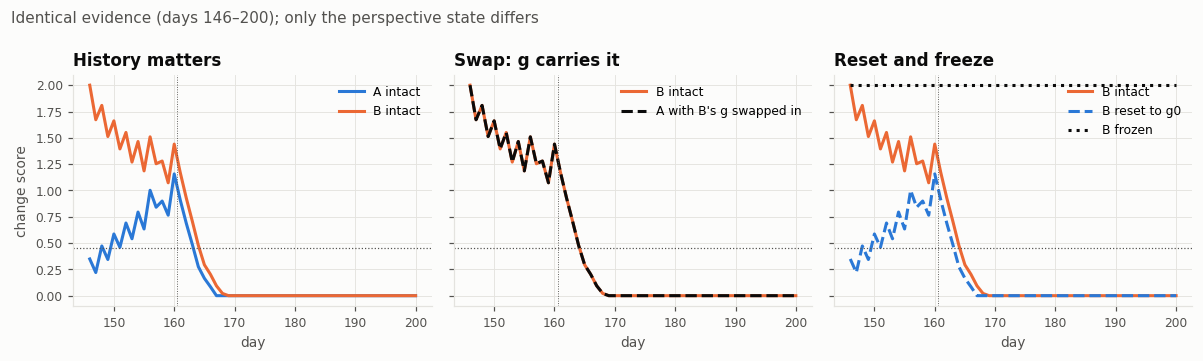


Probe at day 146: "I don't feel like going outside today."
condition                probe read as     alpha_t
--------------------------------------------------
A intact                 no_active_change  0.071  
B intact                 supports          0.259  
A with B's g swapped in  supports          0.259  
B reset to g0            no_active_change  0.071  


In [ ]:
CONT = LH[145:]                                    # days 146-200, identical for every condition
g_A, g_B = SNAP[100], SNAP[145]

def continue_from(g_start, evidence=CONT, frozen=False):
    L = PerspectiveLayer(); L.set_state(g_start); L.freeze(frozen)
    outs = [L.observe(e) for e in evidence]
    return {"score": np.array([L.g["score"] if frozen else o["g"]["score"] for o in outs]),
            "status": [L.g["status"] if frozen else o["g"]["status"] for o in outs]}

runs = {"A intact": continue_from(g_A), "B intact": continue_from(g_B),
        "A with B's g swapped in": continue_from(g_B),
        "B reset to g0": continue_from(initial_g()), "B frozen": continue_from(g_B, frozen=True)}

x = np.arange(146, 201)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3), sharey=True)
panels = [("History matters", [("A intact", BLUE, "-"), ("B intact", ORANGE, "-")]),
          ("Swap: g carries it", [("B intact", ORANGE, "-"), ("A with B's g swapped in", INK, "--")]),
          ("Reset and freeze", [("B intact", ORANGE, "-"), ("B reset to g0", BLUE, "--"), ("B frozen", INK, ":")])]
for ax, (title, series) in zip(axes, panels):
    for name, col, ls in series:
        ax.plot(x, runs[name]["score"], color=col, ls=ls, label=name)
    ax.axhline(Config().deactivate, color=INK2, lw=0.8, ls=":")
    ax.axvline(160.5, color=INK2, lw=0.6, ls=":")
    ax.set_title(title); ax.set_xlabel("day"); ax.legend(loc="upper right")
axes[0].set_ylabel("change score")
fig.suptitle("Identical evidence (days 146–200); only the perspective state differs", x=0.01, ha="left",
             fontsize=10, color=INK2)
fig.tight_layout(); plt.show()

rows = []
for name, g in [("A intact", g_A), ("B intact", g_B), ("A with B's g swapped in", g_B), ("B reset to g0", initial_g())]:
    r = read_probe_under(g)
    rows.append({"condition": name, "probe read as": r["z"]["relation_to_provisional"],
                 "alpha_t": f"{r['alpha']:.3f}"})
show_table(rows, ["condition", "probe read as", "alpha_t"], title=f'\nProbe at day 146: "{DATA["probe"]["utterance"]}"')

- **Swap.** Agent A, with B's `g`, reads the world exactly as B does from that point on. Whatever B's history did to its readings is carried in `g`.
- **Reset.** B with `g0` behaves like A: the history is gone.
- **Freeze.** A perspective that can no longer be revised holds the change forever, through 40 days of recovery.

One honest caveat: here the swap is exact *by construction*, because this layer is Markov in `g`. That is the point of an explicit module. With a *learned* `g` (the latent swap in the CEAR minimal agents, or the reset and swap controls in the CEAR-LLM pilot) whether `g` carries the history is an empirical question. The protocol is the same.

#### ✏️ Optional: be the parser

Type a sentence and parse it yourself: you are now the semantic parser. The layer does the rest. If you have an OpenAI key you can also call the experiment-04 parser prompt (optional; everything else runs without it).

In [ ]:
my_sentence = "I skipped my walk again, I just don't want to go out anymore."   # ✏️
my_parse = Evidence(orientation="change",          # baseline | change | neutral | unclear
                    strength=0.8, confidence=0.8,
                    temporal_scope="recent_pattern") # single_event | recent_pattern | ongoing_preference | future_intention | unclear

rows = []
for day, label in [(100, "calm history (day 100)"), (145, "after genuine change (day 145)"), (200, "after recovery (day 200)")]:
    r = read_probe_under(SNAP[day], my_parse)
    rows.append({"under": label, "read as": r["z"]["relation_to_provisional"],
                 "longitudinal evidence": f"{r['z']['longitudinal_evidence']:.2f}",
                 "alpha_t": f"{r['alpha']:.3f}", "status after": r["g"]["status"]})
show_table(rows, ["under", "read as", "longitudinal evidence", "alpha_t", "status after"], title=f'"{my_sentence}"\n')

"I skipped my walk again, I just don't want to go out anymore."

under                           read as           longitudinal evidence  alpha_t  status after
----------------------------------------------------------------------------------------------
calm history (day 100)          no_active_change  0.48                   0.174    monitoring  
after genuine change (day 145)  supports          0.48                   0.303    active      
after recovery (day 200)        no_active_change  0.48                   0.174    monitoring  


In [ ]:
# @title Optional: the experiment-04 LLM parser (needs `pip install openai` and an OPENAI_API_KEY) { display-mode: "form" }
USE_LIVE_PARSER = False   # ✏️ set True to try

PARSER_PROMPT = """You are a semantic observation extractor.
Analyze ONLY the current utterance.
Do NOT compare it with any prior user state.
Do NOT decide whether it supports or contradicts a persistent profile.
Do NOT decide whether a longitudinal change should be activated.
Extract only the utterance's own semantic content.

Orientation:
toward_outdoor_engagement: expresses going outside, walking, enjoyment of outdoor activity, return to outdoor routine, or desire for it.
away_from_outdoor_engagement: expresses avoiding, skipping, disliking, withdrawing from, or preferring not to engage in outdoor activity.
neutral: relevant but without meaningful directional preference.
unclear: direction cannot be determined.

Temporal scope:
single_event: one present or isolated event such as today or this morning.
recent_pattern: repeated or recent behavior such as lately, again, continued, recently, or repeatedly.
ongoing_preference: broader current preference or sustained orientation.
future_intention: explicit intention about future behavior.
unclear: temporal scope cannot be determined.

Return only the requested structured observation."""

if USE_LIVE_PARSER:
    import os
    from typing import Literal
    from openai import OpenAI
    from pydantic import BaseModel, Field

    class SemanticObservation(BaseModel):
        interpretation: str
        orientation: Literal["toward_outdoor_engagement", "away_from_outdoor_engagement", "neutral", "unclear"]
        temporal_scope: Literal["single_event", "recent_pattern", "ongoing_preference", "future_intention", "unclear"]
        semantic_strength: float = Field(ge=0.0, le=1.0)
        confidence: float = Field(ge=0.0, le=1.0)
        rationale: str

    client = OpenAI()
    resp = client.responses.parse(
        model=os.environ.get("OPENAI_MODEL", "gpt-5-nano"), reasoning={"effort": "minimal"},
        input=[{"role": "system", "content": PARSER_PROMPT},
               {"role": "user", "content": f"CURRENT UTTERANCE:\n{my_sentence}"}],
        text_format=SemanticObservation)
    obs = resp.output_parsed
    print(obs)
    live = Evidence(TO_EVIDENCE[obs.orientation], obs.semantic_strength, obs.confidence, obs.temporal_scope)
    for day in (100, 145, 200):
        r = read_probe_under(SNAP[day], live)
        print(f"day {day}: read as {r['z']['relation_to_provisional']:18s} alpha_t={r['alpha']:.3f}")
else:
    print("Live parser off. Everything else in this notebook runs without it.")

Live parser off. Everything else in this notebook runs without it.


## 3 · Host 2: a pymdp agent, same layer

Now we attach the **same class, with the same constants**, to an agent built in [`pymdp`](https://github.com/infer-actively/pymdp), the library most of this community already uses for discrete active inference (here version 1.0.4, the JAX rewrite).

**The task** is a two-armed cue task, written as an ordinary pymdp generative model:

| | |
|---|---|
| hidden factor 0 | context: reward on the left or on the right (50/50 each trial) |
| hidden factor 1 | choice: start → left or right (controllable) |
| modality 0 | a cue that points to the rewarded side; the model believes it is right 90% of the time |
| modality 1 | outcome: none / reward / no reward |

The agent infers the context from the cue and chooses an arm by expected free energy.

**The world** does not always agree with the model:

| trials | cue reliability | |
|---|---|---|
| 0–69 | 0.9 | with a 3-trial blip at 30–32 where cues mislead |
| 70–129 | 0.2 | the signs now mislead |
| 130–199 | 0.9 | back to normal |

**The adapter** is the only new code, and it has exactly two hooks:

- **read**: pymdp accepts observations as distributions (`categorical_obs=True`). The layer decides **how sharply the cue is delivered** to state inference. While no change is held, the established frame stands and the cue arrives as a crisp one-hot. While a change is held, it arrives blurred toward uniform, released gradually as the change evidence decays. `A`, `B`, `C` and `D` are never touched.
- **write**: after the outcome, the agent's **own posterior** over the context is compared with the cue, and that agreement becomes `Evidence`.

No reward, preference or expected free energy ever reaches the layer.

In [ ]:
# @title Install pymdp (about 30 s on Colab; falls back to a built-in NumPy host if unavailable) { display-mode: "form" }
import importlib.metadata, subprocess, sys
try:
    import pymdp  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "inferactively-pymdp==1.0.4"], check=False)
try:
    import jax, jax.numpy as jnp, equinox as eqx
    from pymdp.agent import Agent
    HAVE_PYMDP = True
    print("pymdp", importlib.metadata.version("inferactively-pymdp"), "· jax", jax.__version__)
except Exception as e:
    HAVE_PYMDP = False
    print(f"pymdp unavailable ({e}). Using the built-in NumPy host, which implements the same model and update rule.")

pymdp 1.0.4 · jax 0.11.0


In [ ]:
def build_cue_agent(cue_reliability=0.9, pref_reward=3.0):
    """The two-armed cue task as a standard pymdp generative model. The layer never edits it."""
    r = cue_reliability
    A_cue = np.array([[r, 1 - r], [1 - r, r]])               # P(cue | context)
    A_out = np.zeros((3, 2, 3))                              # P(outcome | context, choice)
    A_out[0, :, 0] = 1.0                                     # at start: no outcome
    for ctx in (0, 1):
        for arm, choice in ((0, 1), (1, 2)):
            A_out[1 if arm == ctx else 2, ctx, choice] = 1.0
    B_ctx = np.eye(2)[:, :, None]                            # context does not change within a trial
    B_choice = np.zeros((3, 3, 2))
    for u in (0, 1):
        B_choice[1 + u, :, u] = 1.0                          # go-left / go-right
    C = [np.zeros(2), np.array([0.0, pref_reward, 0.0])]     # prefer reward
    D = [np.array([0.5, 0.5]), np.array([1.0, 0.0, 0.0])]   # unknown context, start at start
    return Agent(A=[jnp.asarray(A_cue), jnp.asarray(A_out)], B=[jnp.asarray(B_ctx), jnp.asarray(B_choice)],
                 C=[jnp.asarray(c) for c in C], D=[jnp.asarray(d) for d in D],
                 A_dependencies=[[0], [0, 1]], B_dependencies=[[0], [1]],
                 num_controls=[1, 2], control_fac_idx=[1],
                 categorical_obs=True, action_selection="deterministic", batch_size=1)

if HAVE_PYMDP:
    @eqx.filter_jit
    def _decide(agent, cue_vec):
        qs = agent.infer_states([cue_vec[None], jnp.eye(3)[0][None]], agent.D)
        q_pi, neg_efe = agent.infer_policies(qs)
        return qs, agent.sample_action(q_pi)

    @eqx.filter_jit
    def _after_outcome(agent, qs, action, outcome):
        prior = agent.update_empirical_prior(action, qs)
        no_cue = jnp.full((1, 2), 0.5)                       # the cue is not shown again
        return agent.infer_states([no_cue, jax.nn.one_hot(outcome, 3)[None]], prior)

    class PymdpCueHost:
        def __init__(self, **kw):
            self.agent = build_cue_agent(**kw)
        def decide(self, cue_vec):
            qs, action = _decide(self.agent, jnp.asarray(cue_vec, dtype=jnp.float32))
            return np.asarray(qs[0][0, -1]), int(action[0, 1]), (qs, action)
        def context_posterior(self, memo, outcome):
            qs, action = memo
            return np.asarray(_after_outcome(self.agent, qs, action, outcome)[0][0, -1])

In [ ]:
# @title Built-in NumPy host (fallback only: the same model and the same update rule as pymdp's) { display-mode: "form" }
class NumpyCueHost:
    def __init__(self, cue_reliability=0.9, pref_reward=3.0):
        r = cue_reliability
        self.logA = np.log(np.array([[r, 1 - r], [1 - r, r]]))
    def decide(self, cue_vec):
        # pymdp's rule for categorical observations: log-likelihood = sum_o p(o) * ln A[o, s]
        logq = np.log(0.5) + np.asarray(cue_vec) @ self.logA
        q = np.exp(logq - logq.max()); q /= q.sum()
        return q, int(q[1] > q[0]), None                    # both arms are equally informative: utility decides
    def context_posterior(self, memo, outcome):
        return None                                         # filled in by run_agent from the outcome

def make_host(**kw):
    return PymdpCueHost(**kw) if HAVE_PYMDP else NumpyCueHost(**kw)

In [ ]:
class CueWorld:
    """Contexts and cues do not depend on the agent's actions, so agents run with the
    same seed see exactly the same observations."""
    def __init__(self, reliability, seed=0):
        rng = np.random.default_rng(seed)
        self.reliability = np.array(reliability)
        self.c = rng.integers(0, 2, len(reliability))                        # 0 = left, 1 = right
        self.cue = np.where(rng.random(len(reliability)) < self.reliability, self.c, 1 - self.c)
    def __len__(self): return len(self.c)

def schedule(n=200, blip=(30, 33), shift=(70, 130), r_ok=0.9, r_bad=0.2):
    s = np.full(n, r_ok); s[blip[0]:blip[1]] = 0.0; s[shift[0]:shift[1]] = r_bad
    return s

class PerspectiveAdapter:
    """The only code that knows both the host and the layer."""
    def __init__(self, layer=None, strength=0.8, confidence=0.8):
        self.layer = layer or PerspectiveLayer(Config())   # same class, same constants as Part 2
        self.strength, self.confidence = strength, confidence

    def weight(self):                                      # how sharply the cue is given
        return 1.0 if self.layer.g["status"] != "active" else 1.0 - self.layer.change_strength

    def deliver(self, cue):                                # READ hook: shapes the observation, not the model
        w = self.weight()
        return w * np.eye(2)[cue] + (1 - w) * 0.5
        # (pymdp's `mask=` argument on infer_states would blend the likelihood instead,
        #  but in 1.0.4 it also overwrites the agent's stored A, so we do not use it.)

    def evidence(self, cue, believed_context, t):          # WRITE hook: from the agent's own posterior
        return Evidence("baseline" if cue == believed_context else "change",
                        self.strength, self.confidence, "single_event", f"trial_{t}")

def run_agent(world, host, adapter=None, interventions=None):
    log = {k: [] for k in ["q_cued", "correct", "score", "status"]}
    for t in range(len(world)):
        if adapter is not None and interventions and t in interventions:
            interventions[t](adapter.layer)
        cue, c = int(world.cue[t]), int(world.c[t])
        cue_vec = adapter.deliver(cue) if adapter else np.eye(2)[cue]
        q, arm, memo = host.decide(cue_vec)
        outcome = 1 if arm == c else 2                     # reward / no reward
        post = host.context_posterior(memo, outcome)
        believed = int(np.argmax(post)) if post is not None else (arm if outcome == 1 else 1 - arm)
        if adapter is not None:
            adapter.layer.observe(adapter.evidence(cue, believed, t))
        log["q_cued"].append(q[cue]); log["correct"].append(int(arm == c))
        log["score"].append(adapter.layer.g["score"] if adapter else np.nan)
        log["status"].append(adapter.layer.g["status"] if adapter else "-")
    return {k: np.array(v) for k, v in log.items()}

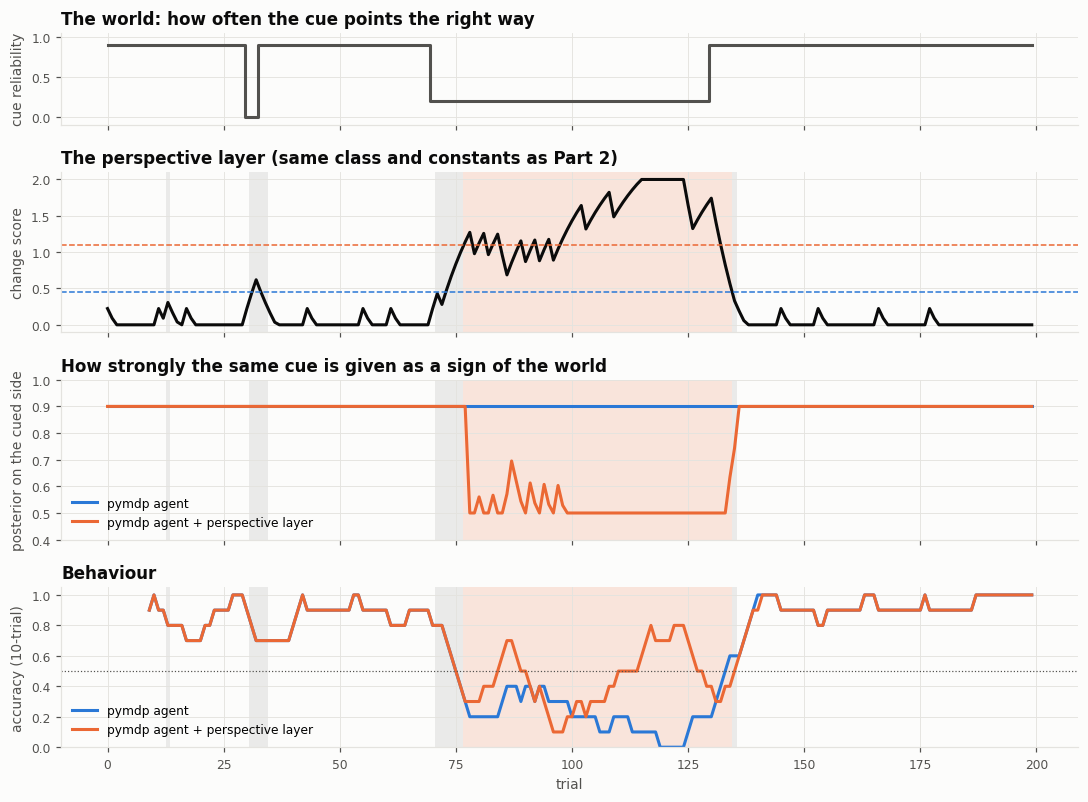

blip (30-32): change held?            no   (peak score 0.62; cue posterior stays 0.90)
sustained shift: change held after   7 trials
return to normal: released after     5 trials
accuracy, misleading phase 70-129        pymdp 0.20   + layer 0.42
accuracy, first 10 trials after return   pymdp 0.90   + layer 0.90


In [ ]:
SEED = 6                                                  # ✏️ try other seeds
world = CueWorld(schedule(), seed=SEED)
host = make_host()
vanilla = run_agent(world, host)
augmented = run_agent(world, host, PerspectiveAdapter())

def rolling(v, w=10):
    return np.array([v[max(0, t - w + 1):t + 1].mean() for t in range(len(v))])

x = np.arange(len(world))
fig, axes = plt.subplots(4, 1, figsize=(10, 7.4), sharex=True, gridspec_kw={"height_ratios": [0.8, 1.4, 1.4, 1.4]})
axes[0].step(x, world.reliability, where="mid", color=INK2)
axes[0].set_ylabel("cue reliability"); axes[0].set_ylim(-0.1, 1.05)
axes[0].set_title("The world: how often the cue points the right way")
shade_status(axes[1], augmented["status"], x0=0)
axes[1].plot(x, augmented["score"], color=INK)
axes[1].axhline(Config().activate, color=ORANGE, lw=1, ls="--"); axes[1].axhline(Config().deactivate, color=BLUE, lw=1, ls="--")
axes[1].set_ylabel("change score"); axes[1].set_title("The perspective layer (same class and constants as Part 2)")
for ax in axes[2:]:
    shade_status(ax, augmented["status"], x0=0)
axes[2].plot(x, vanilla["q_cued"], color=BLUE, label="pymdp agent")
axes[2].plot(x, augmented["q_cued"], color=ORANGE, label="pymdp agent + perspective layer")
axes[2].set_ylabel("posterior on the cued side"); axes[2].set_ylim(0.4, 1.0); axes[2].legend(loc="lower left")
axes[2].set_title("How strongly the same cue is given as a sign of the world")
axes[3].plot(x[9:], rolling(vanilla["correct"])[9:], color=BLUE, label="pymdp agent")
axes[3].plot(x[9:], rolling(augmented["correct"])[9:], color=ORANGE, label="pymdp agent + perspective layer")
axes[3].axhline(0.5, color=INK2, lw=0.8, ls=":"); axes[3].set_ylim(0, 1.05)
axes[3].set_ylabel("accuracy (10-trial)"); axes[3].set_xlabel("trial"); axes[3].legend(loc="lower left")
axes[3].set_title("Behaviour")
fig.tight_layout(); plt.show()

st = augmented["status"]
on = next((t for t in range(70, 130) if st[t] == "active"), None)
off = next((t for t in range(130, 200) if st[t] != "active"), None)
print(f"blip (30-32): change held?            {'yes' if any(s == 'active' for s in st[30:40]) else 'no'}   "
      f"(peak score {augmented['score'][30:40].max():.2f}; cue posterior stays {augmented['q_cued'][30:40].min():.2f})")
print(f"sustained shift: change held after   {None if on is None else on - 70} trials")
print(f"return to normal: released after     {None if off is None else off - 130} trials")
for name, (a, b) in {"misleading phase 70-129": (70, 130), "first 10 trials after return": (130, 140)}.items():
    print(f"accuracy, {name:30s} pymdp {vanilla['correct'][a:b].mean():.2f}   + layer {augmented['correct'][a:b].mean():.2f}")

What to notice:

- **The blip** is registered (the score rises into monitoring), but the cue is still given as a sign: the established frame stands under transient evidence.
- **The sustained shift** is held after a few trials. From then on the identical cue is given as noise, while the plain pymdp agent keeps reading it as 90% reliable and follows it into error.
- **The return** is released with a lag. For a few trials the augmented agent discounts a cue that is reliable again. In a single world this may or may not cost a choice; averaged over many worlds (two cells down) it costs accuracy right after the return. A module tuned for reward would not do this. This one is not tuned for reward; nothing about reward ever reaches it.
- **Modularity.** The layer is the class from Part 1, with the constants from Part 2. The pymdp model is stock. Only the adapter is new.

#### ✏️ Intervention: transplant a perspective

Take an agent living in a perfectly normal world. At trial 100 we install the `g` of an agent that is in the middle of the misleading phase. Same world, same cues, same generative model; only the perspective is foreign.

donor g at trial 100: status=active, score=2.00


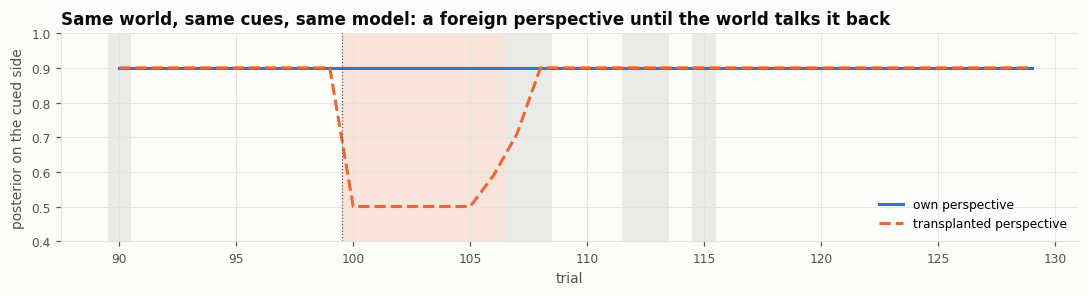

In [ ]:
donor = PerspectiveAdapter()
run_agent(CueWorld(schedule()[:100], seed=SEED), host, donor)
g_donor = copy.deepcopy(donor.layer.g)
print(f"donor g at trial 100: status={g_donor['status']}, score={g_donor['score']:.2f}")

calm_world = CueWorld(np.full(200, 0.9), seed=SEED + 100)
TRANSPLANT_AT = 100                                                       # ✏️
calm = run_agent(calm_world, host, PerspectiveAdapter())
transplanted = run_agent(calm_world, host, PerspectiveAdapter(),
                         interventions={TRANSPLANT_AT: lambda layer: layer.set_state(g_donor)})

x = np.arange(len(calm_world)); lo, hi = TRANSPLANT_AT - 10, TRANSPLANT_AT + 30
fig, ax = plt.subplots(figsize=(10, 2.8))
shade_status(ax, transplanted["status"][lo:hi], x0=lo)
ax.plot(x[lo:hi], calm["q_cued"][lo:hi], color=BLUE, label="own perspective")
ax.plot(x[lo:hi], transplanted["q_cued"][lo:hi], color=ORANGE, ls="--", label="transplanted perspective")
ax.axvline(TRANSPLANT_AT - 0.5, color=INK2, lw=0.8, ls=":")
ax.set_ylim(0.4, 1.0); ax.set_xlabel("trial"); ax.set_ylabel("posterior on the cued side")
ax.set_title("Same world, same cues, same model: a foreign perspective until the world talks it back")
ax.legend(loc="lower right"); fig.tight_layout(); plt.show()

#### Direction-dependent revision across worlds

Entering a held change and leaving it are governed by different thresholds and by different evidence. Over many worlds, how long does each take? (About 15 seconds.)

In [ ]:
N_WORLDS = 30                                                             # ✏️
lat_on, lat_off, false_holds, acc_v, acc_a = [], [], 0, [], []
for seed in range(N_WORLDS):
    w = CueWorld(schedule(), seed)
    v, a = run_agent(w, host), run_agent(w, host, PerspectiveAdapter())
    st = a["status"]
    acc_v.append(v["correct"][130:140].mean()); acc_a.append(a["correct"][130:140].mean())
    false_holds += any(s == "active" for s in st[:70])
    on = next((t for t in range(70, 130) if st[t] == "active"), None)
    off = next((t for t in range(130, 200) if st[t] != "active"), None)
    if on is not None: lat_on.append(on - 70)
    if off is not None: lat_off.append(off - 130)
print(f"worlds with a false hold before the shift: {false_holds}/{N_WORLDS}")
print(f"normal → misleading: change held after     {np.mean(lat_on):.1f} ± {np.std(lat_on):.1f} trials  (n={len(lat_on)})")
print(f"misleading → normal: change released after {np.mean(lat_off):.1f} ± {np.std(lat_off):.1f} trials  (n={len(lat_off)})")
print(f"accuracy in the first 10 trials after the return: pymdp {np.mean(acc_v):.2f}, + layer {np.mean(acc_a):.2f}")

worlds with a false hold before the shift: 0/30
normal → misleading: change held after     8.5 ± 3.2 trials  (n=30)
misleading → normal: change released after 4.1 ± 1.5 trials  (n=30)
accuracy in the first 10 trials after the return: pymdp 0.91, + layer 0.82


#### ✏️ Going further: "Isn't this just precision learning?"

The first question an active inference audience should ask. Below, the standard alternative: the agent **learns its likelihood** with Dirichlet counts, with forgetting so that it can track a changing world. (pymdp can learn `A` too, via `learn_A=True` and `pA`; it has no forgetting term, so we write the five lines out by hand.)

Learning `A` changes **what the cue means about the world**: eventually the learner concludes that the cue points the wrong way and exploits it, and then it is slow to un-learn that. The perspective layer never touches `A`; it changes **whether the cue shows up as a sign at all**. In Husserl's terms, the first updates intentional matter and the second intentional quality. They are different jobs, and nothing stops you from attaching the layer to a learning agent. The toy does not settle the question; it lets you see the difference.

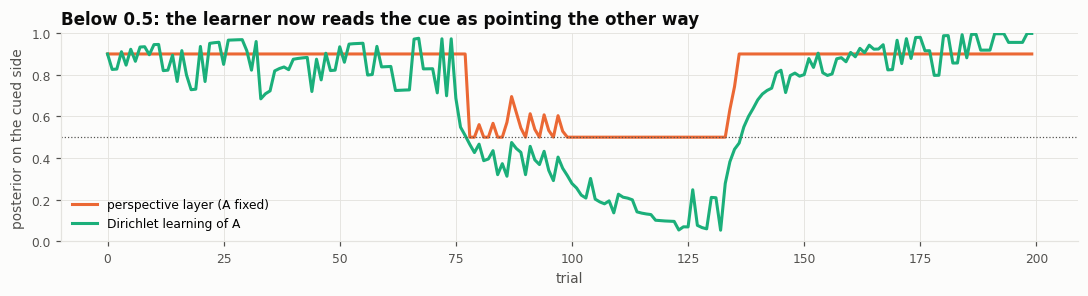

Accuracy by phase
agent                            blip 30-39  misleading 70-129  after return 130-139  late 150-199
--------------------------------------------------------------------------------------------------
pymdp agent                      0.70        0.20               0.90                  0.94        
pymdp agent + perspective layer  0.70        0.42               0.90                  0.94        
Dirichlet learner                0.70        0.70               0.40                  0.94        


In [ ]:
class DirichletLearner:
    def __init__(self, forgetting=0.9, prior_count=9.0):
        self.a = np.array([[prior_count, 1.0], [1.0, prior_count]]); self.forgetting = forgetting
    def run(self, world):
        q_cued, correct = [], []
        for t in range(len(world)):
            cue, c = int(world.cue[t]), int(world.c[t])
            A = self.a / self.a.sum(0, keepdims=True)
            q = A[cue] / A[cue].sum(); arm = int(q[1] > q[0])
            q_cued.append(q[cue]); correct.append(int(arm == c))
            self.a *= self.forgetting; self.a[cue, c] += 1.0        # outcome reveals the context
        return {"q_cued": np.array(q_cued), "correct": np.array(correct)}

learner = DirichletLearner(forgetting=0.9).run(world)                     # ✏️ try 0.8, 0.95

x = np.arange(len(world))
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.plot(x, augmented["q_cued"], color=ORANGE, label="perspective layer (A fixed)")
ax.plot(x, learner["q_cued"], color=AQUA, label="Dirichlet learning of A")
ax.axhline(0.5, color=INK2, lw=0.8, ls=":")
ax.set_ylim(0, 1.0); ax.set_xlabel("trial"); ax.set_ylabel("posterior on the cued side")
ax.set_title("Below 0.5: the learner now reads the cue as pointing the other way")
ax.legend(loc="lower left"); fig.tight_layout(); plt.show()

rows = []
for name, r in [("pymdp agent", vanilla), ("pymdp agent + perspective layer", augmented), ("Dirichlet learner", learner)]:
    rows.append({"agent": name, "blip 30-39": f"{r['correct'][30:40].mean():.2f}",
                 "misleading 70-129": f"{r['correct'][70:130].mean():.2f}",
                 "after return 130-139": f"{r['correct'][130:140].mean():.2f}",
                 "late 150-199": f"{r['correct'][150:200].mean():.2f}"})
show_table(rows, ["agent", "blip 30-39", "misleading 70-129", "after return 130-139", "late 150-199"],
           title="Accuracy by phase")

## 4 · Your agent: insertion points

Take five minutes with your own agent (PyMDP, RxInfer, a custom AIF model, an LLM agent) and answer four questions.

1. **Perception → Evidence.** What does your host produce at each step that can become a *state-independent* evidence record? In pymdp: the observation together with the posterior from `infer_states` (Part 3). In RxInfer: a posterior marginal. In an LLM agent: a structured parse (Part 2).
2. **Where is `g` read?** Pick **one** place where a world is *given*: how sharply an observation is delivered (pymdp's categorical observations, Part 3), the precision of a likelihood, a salience or attention mask, a FiLM layer on the encoder (the CEAR minimal agents), or the context rendered to a language model (Part 2).
3. **What must never write to `g`?** Reward, preferences (`C`), expected free energy, policy gradients, and the response model's own outputs.
4. **What will you intervene on?** Plan reset, swap and freeze **before** you run anything. If you cannot say what a swap should change, you cannot yet say what your `g` is for.

### Discussion

- What would count as evidence that this is more than memory, or more than a slow prior?
- Day 200 in Part 2: should a perspective that has been through a change ever fully return? The record survives; the reading does not.
- In Part 3, is changing how sharply a cue is delivered "how a world is given", or just attention? Where is the line?
- Two perspective-bearing agents in conversation: what would *mutual legibility* between their `g`s look like? (Alignment as perspective compatibility, rather than behavioural conformity.)

---

### References

- Pae, H. (2025). Reflective analysis on empirical theories in consciousness. *Frontiers in Psychology*, 16, 1571098. https://doi.org/10.3389/fpsyg.2025.1571098
- Pae, H. (2026). Minimal computational preconditions for subjective perspective in artificial agents. *Proceedings of the AAAI Symposium Series*, 8(1). https://doi.org/10.1609/aaaiss.v8i1.42559
- Pae, H. (2026). Same world, differently given: history-dependent perceptual reorganization in artificial agents. arXiv:2604.04637. https://arxiv.org/abs/2604.04637
- Pae, H. (2026). Perspective as a missing structural condition for subjectivity in active inference systems. *AGI-26*.
- Code: [`perspective-llm`](https://github.com/hjpae/perspective-llm) (LLM host, experiments 03–04) · [`cearlab-phase2`](https://github.com/hjpae/cearlab-phase2) (minimal agents)